In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

from IPython.display import display

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/satimage/"

os.makedirs("data", exist_ok=True)

train_url = DATA_URL + "sat.trn"
test_url = DATA_URL + "sat.tst"

urllib.request.urlretrieve(train_url, "data/sat.trn")
urllib.request.urlretrieve(test_url, "data/sat.tst")

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [3]:
feature_columns = [
    f"Attribute{i}" for i in range(1, 37)
]

columns = feature_columns + ["Class"]

train_df = pd.read_csv(
    "data/sat.trn",
    sep=r"\s+",
    header=None,
    names=columns
)

test_df = pd.read_csv(
    "data/sat.tst",
    sep=r"\s+",
    header=None,
    names=columns
)

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

display(train_df.head())

Training dataset shape: (4435, 37)
Testing dataset shape: (2000, 37)


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute28,Attribute29,Attribute30,Attribute31,Attribute32,Attribute33,Attribute34,Attribute35,Attribute36,Class
0,92,115,120,94,84,102,106,79,84,102,...,104,88,121,128,100,84,107,113,87,3
1,84,102,106,79,84,102,102,83,80,102,...,100,84,107,113,87,84,99,104,79,3
2,84,102,102,83,80,102,102,79,84,94,...,87,84,99,104,79,84,99,104,79,3
3,80,102,102,79,84,94,102,79,80,94,...,79,84,99,104,79,84,103,104,79,3
4,84,94,102,79,80,94,98,76,80,102,...,79,84,103,104,79,79,107,109,87,3


In [4]:
print("Training Dataset Information")
print("-----------------------------")

train_df.info()

print("\nTraining Dataset Description")
display(train_df.describe())

print("\nMissing Values")
print(train_df.isnull().sum().sum())

print("\nDuplicate Records")
print(train_df.duplicated().sum())

print("\nTarget Classes")
print(sorted(train_df["Class"].unique()))

Training Dataset Information
-----------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4435 entries, 0 to 4434
Data columns (total 37 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Attribute1   4435 non-null   int64
 1   Attribute2   4435 non-null   int64
 2   Attribute3   4435 non-null   int64
 3   Attribute4   4435 non-null   int64
 4   Attribute5   4435 non-null   int64
 5   Attribute6   4435 non-null   int64
 6   Attribute7   4435 non-null   int64
 7   Attribute8   4435 non-null   int64
 8   Attribute9   4435 non-null   int64
 9   Attribute10  4435 non-null   int64
 10  Attribute11  4435 non-null   int64
 11  Attribute12  4435 non-null   int64
 12  Attribute13  4435 non-null   int64
 13  Attribute14  4435 non-null   int64
 14  Attribute15  4435 non-null   int64
 15  Attribute16  4435 non-null   int64
 16  Attribute17  4435 non-null   int64
 17  Attribute18  4435 non-null   int64
 18  Attribute19  4435 non-null   

,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute28,Attribute29,Attribute30,Attribute31,Attribute32,Attribute33,Attribute34,Attribute35,Attribute36,Class
count,4435.000000,4435.000000,4435.000000,4435.000000,4435.000000,4435.000000,4435.000000,4435.000000,4435.000000,4435.000000,...,4435.000000,4435.000000,4435.000000,4435.000000,4435.000000,4435.000000,4435.000000,4435.000000,4435.000000,4435.000000
mean,69.473957,83.855242,99.322886,82.555581,69.208794,83.499436,99.174521,82.480496,68.963472,83.131003,...,82.673957,69.033145,83.434273,99.183766,82.638106,68.797069,83.153326,99.061556,82.584442,3.650282
std,13.649635,22.725079,16.672166,18.695450,13.552423,22.811809,16.627583,18.714272,13.497858,22.813312,...,18.884322,13.533934,22.812090,16.741240,18.939820,13.437785,22.762684,16.660735,18.895513,2.217055
min,40.000000,27.000000,56.000000,33.000000,40.000000,27.000000,50.000000,29.000000,40.000000,27.000000,...,34.000000,39.000000,27.000000,50.000000,29.000000,40.000000,27.000000,50.000000,29.000000,1.000000
25%,60.000000,71.000000,85.000000,70.000000,60.000000,71.000000,85.000000,69.000000,60.000000,71.000000,...,70.000000,60.000000,71.000000,85.000000,69.000000,60.000000,71.000000,85.000000,69.000000,2.000000
50%,68.000000,87.000000,101.000000,83.000000,68.000000,85.000000,101.000000,81.000000,67.000000,85.000000,...,81.000000,68.000000,85.000000,101.000000,81.000000,67.000000,85.000000,100.000000,81.000000,3.000000
75%,80.000000,103.000000,113.000000,92.000000,80.000000,103.000000,113.000000,92.000000,79.000000,103.000000,...,92.000000,79.500000,103.000000,113.000000,92.000000,79.000000,103.000000,113.000000,92.000000,5.000000
max,104.000000,137.000000,140.000000,154.000000,102.000000,137.000000,145.000000,157.000000,104.000000,130.000000,...,154.000000,104.000000,128.000000,145.000000,157.000000,104.000000,130.000000,145.000000,157.000000,7.000000



Missing Values
0

Duplicate Records
0

Target Classes
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(7)]


Class Distribution:


Class
1    1072
2     479
3     961
4     415
5     470
7    1038
Name: count, dtype: int64

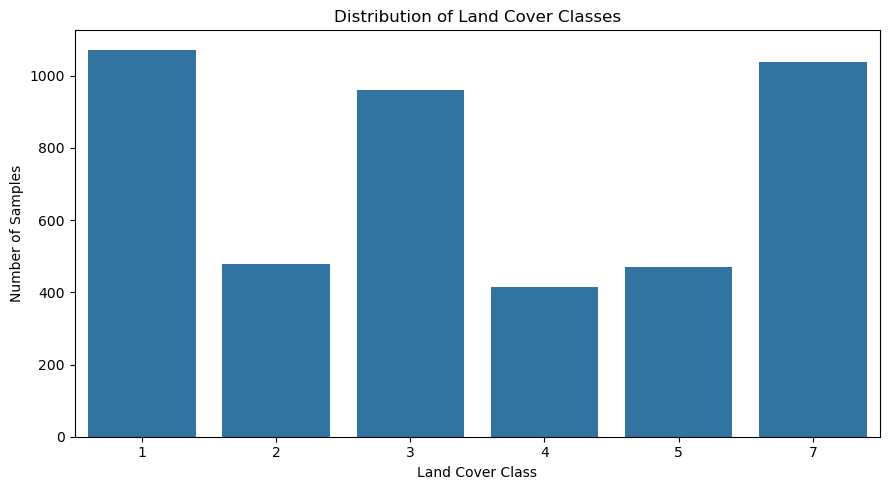

In [5]:
class_distribution = train_df["Class"].value_counts().sort_index()

print("Class Distribution:")
display(class_distribution)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=class_distribution.index.astype(str),
    y=class_distribution.values
)

plt.title("Distribution of Land Cover Classes")
plt.xlabel("Land Cover Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

In [6]:
X_train = train_df[feature_columns]
y_train = train_df["Class"]

X_test = test_df[feature_columns]
y_test = test_df["Class"]

print("Training Features:", X_train.shape)
print("Training Target:", y_train.shape)

print("Testing Features:", X_test.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Classes:", sorted(y_train.unique()))
print("Testing Classes:", sorted(y_test.unique()))

Training Features: (4435, 36)
Training Target: (4435,)
Testing Features: (2000, 36)
Testing Target: (2000,)

Training Classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(7)]
Testing Classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(7)]


In [7]:
models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=3000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Gaussian Naive Bayes": GaussianNB(),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            probability=True,
            random_state=RANDOM_STATE
        ))
    ])

}

print("Five classification models defined successfully!")

for model_name in models:
    print("-", model_name)

Five classification models defined successfully!
- Logistic Regression
- Decision Tree
- KNN
- Gaussian Naive Bayes
- Support Vector Machine


In [8]:
trained_models = {}

for model_name, model in models.items():

    print(f"\nTraining {model_name}...")

    model.fit(X_train, y_train)

    trained_models[model_name] = model

    print(f"{model_name} trained successfully!")

print("\nAll five models trained successfully!")


Training Logistic Regression...
Logistic Regression trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training KNN...
KNN trained successfully!

Training Gaussian Naive Bayes...
Gaussian Naive Bayes trained successfully!

Training Support Vector Machine...
Support Vector Machine trained successfully!

All five models trained successfully!


In [9]:
results = []

for model_name, model in trained_models.items():

    print(f"Evaluating {model_name}...")

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(
        y_test,
        y_proba,
        labels=model.classes_,
        multi_class="ovr",
        average="macro"
    )

    precision = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

results_df = pd.DataFrame(results)

print("\nModel Evaluation Completed!")
display(results_df.round(4))

Evaluating Logistic Regression...
Evaluating Decision Tree...
Evaluating KNN...
Evaluating Gaussian Naive Bayes...
Evaluating Support Vector Machine...

Model Evaluation Completed!


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8395,0.9755,0.8116,0.7938,0.7971,0.8032
1,Decision Tree,0.8490,0.8995,0.8317,0.8293,0.8304,0.8146
2,KNN,0.9045,0.9786,0.8951,0.8886,0.8916,0.8827
3,Gaussian Naive Bayes,0.7965,0.9551,0.7864,0.7877,0.7833,0.7531
4,Support Vector Machine,0.8955,0.9850,0.8852,0.8724,0.8769,0.8718


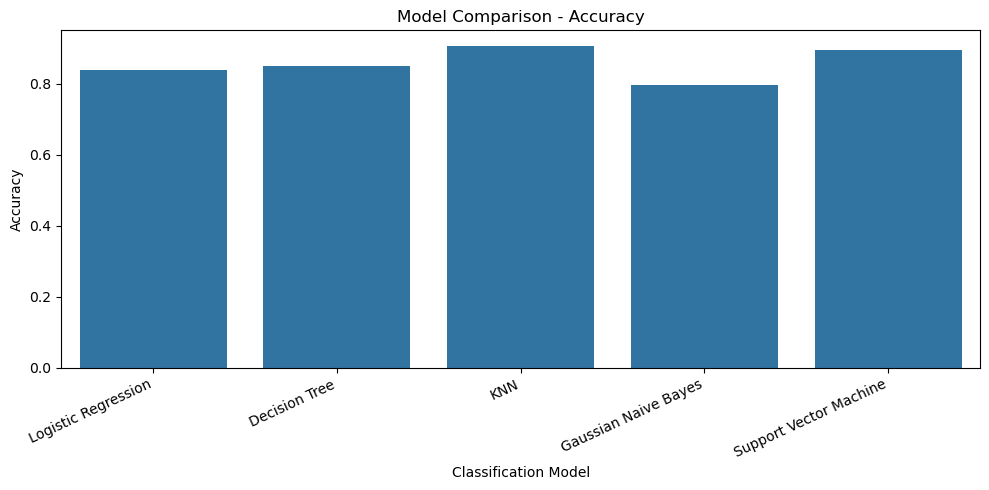

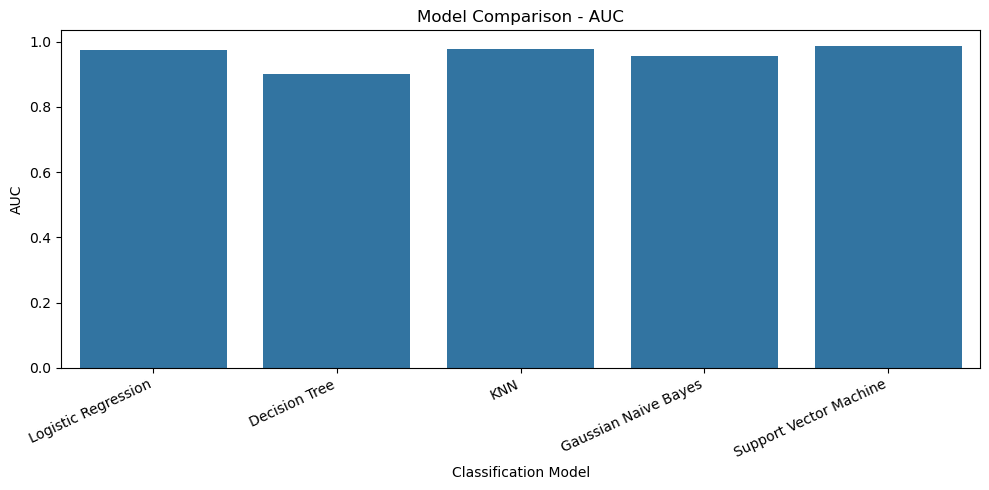

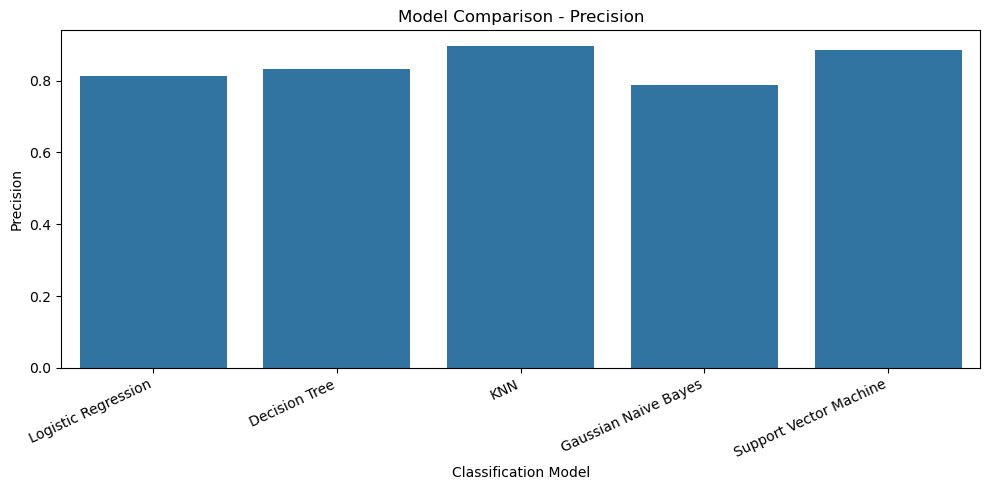

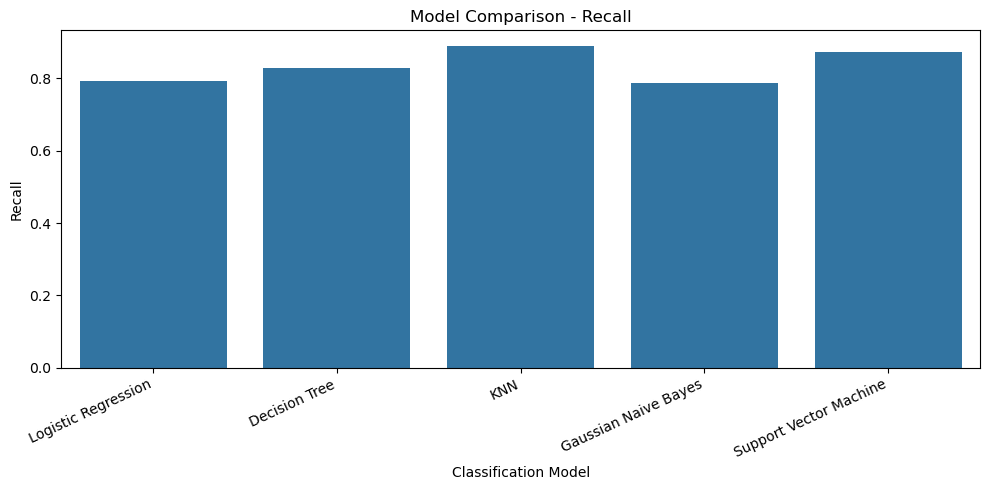

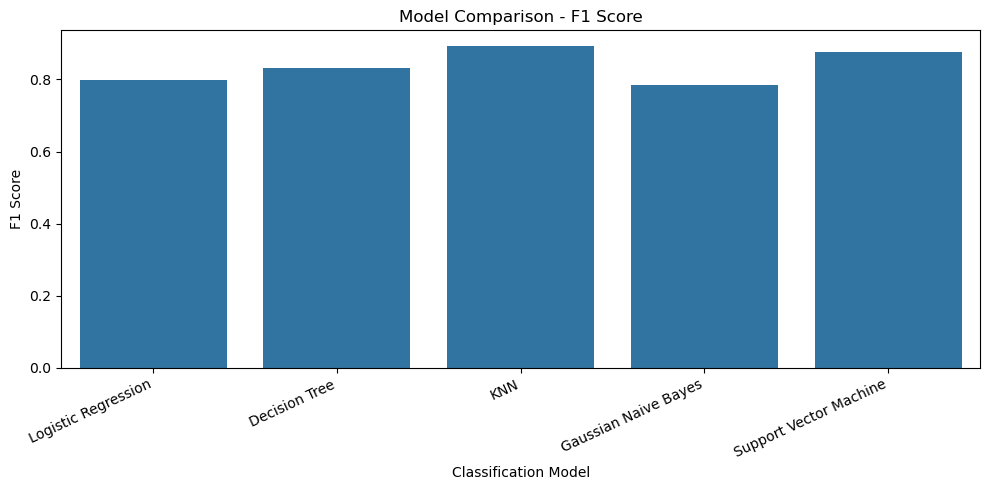

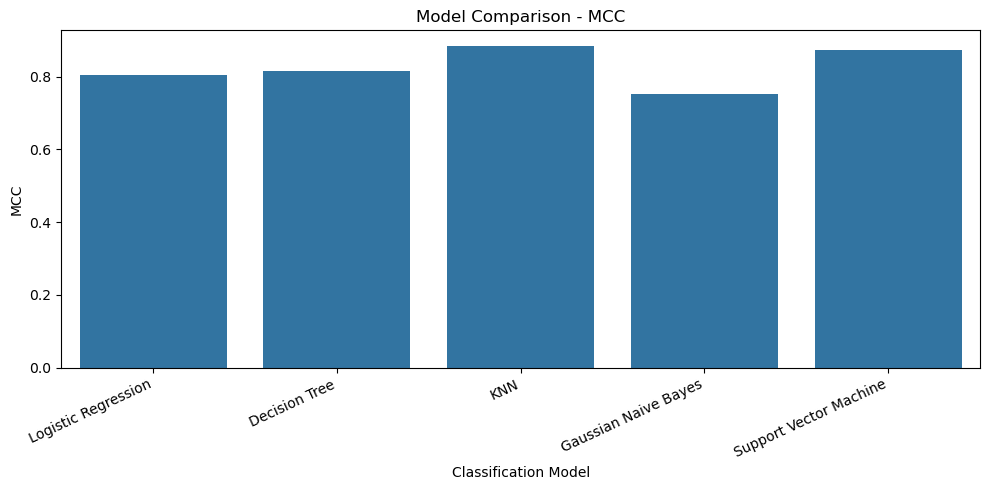

In [10]:
metrics = [
    "Accuracy",
    "AUC",
    "Precision",
    "Recall",
    "F1 Score",
    "MCC"
]

for metric in metrics:

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(f"Model Comparison - {metric}")
    plt.xlabel("Classification Model")
    plt.ylabel(metric)

    plt.xticks(rotation=25, ha="right")

    plt.tight_layout()
    plt.show()

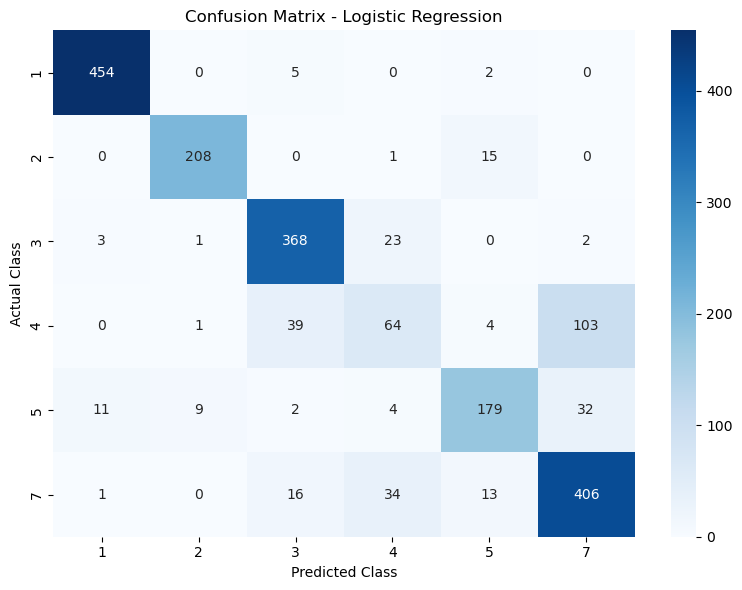

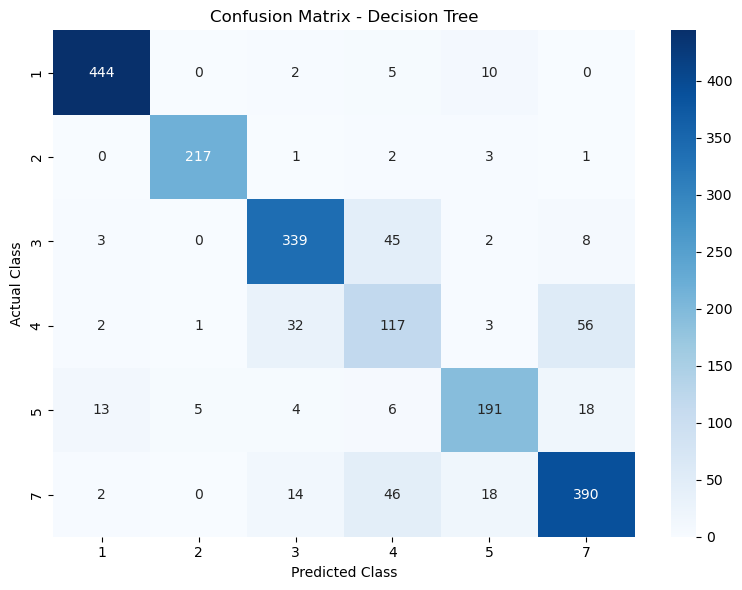

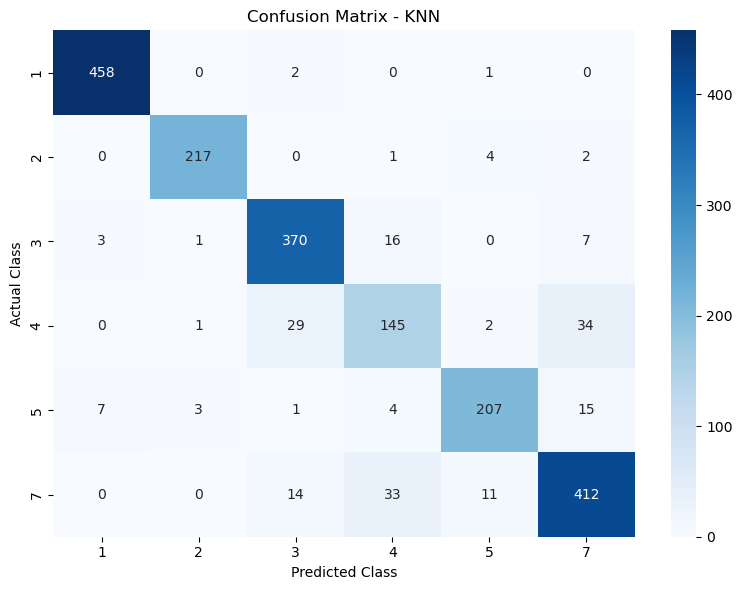

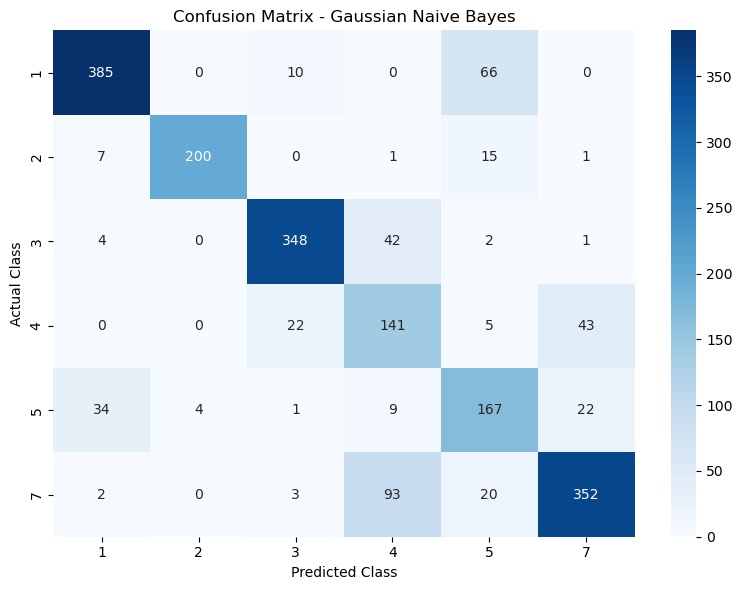

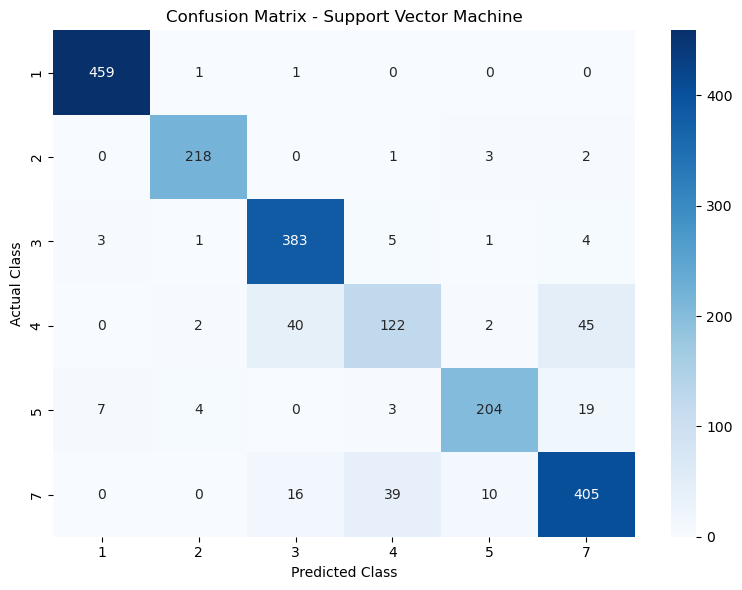

In [11]:
class_labels = sorted(y_test.unique())

for model_name, model in trained_models.items():

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.tight_layout()
    plt.show()

In [12]:
for model_name, model in trained_models.items():

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    y_pred = model.predict(X_test)

    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

           1       0.97      0.98      0.98       461
           2       0.95      0.93      0.94       224
           3       0.86      0.93      0.89       397
           4       0.51      0.30      0.38       211
           5       0.84      0.76      0.80       237
           7       0.75      0.86      0.80       470

    accuracy                           0.84      2000
   macro avg       0.81      0.79      0.80      2000
weighted avg       0.83      0.84      0.83      2000


Decision Tree
              precision    recall  f1-score   support

           1       0.96      0.96      0.96       461
           2       0.97      0.97      0.97       224
           3       0.86      0.85      0.86       397
           4       0.53      0.55      0.54       211
           5       0.84      0.81      0.82       237
           7       0.82      0.83      0.83       470

    accuracy                           0.

In [13]:
best_model_row = results_df.loc[
    results_df["Accuracy"].idxmax()
]

print("Best Performing Model")
print("---------------------")

print("Model:", best_model_row["Model"])
print("Accuracy:", round(best_model_row["Accuracy"], 4))
print("AUC:", round(best_model_row["AUC"], 4))
print("Precision:", round(best_model_row["Precision"], 4))
print("Recall:", round(best_model_row["Recall"], 4))
print("F1 Score:", round(best_model_row["F1 Score"], 4))
print("MCC:", round(best_model_row["MCC"], 4))

Best Performing Model
---------------------
Model: KNN
Accuracy: 0.9045
AUC: 0.9786
Precision: 0.8951
Recall: 0.8886
F1 Score: 0.8916
MCC: 0.8827


In [14]:
os.makedirs("models", exist_ok=True)

model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Gaussian Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

for model_name, model in trained_models.items():

    file_name = model_files[model_name]

    joblib.dump(
        model,
        os.path.join("models", file_name)
    )

    print(f"Saved: {file_name}")

print("\nAll models saved successfully!")

Saved: logistic_regression.joblib
Saved: decision_tree.joblib
Saved: knn.joblib
Saved: naive_bayes.joblib
Saved: svm.joblib

All models saved successfully!


In [15]:
os.makedirs("data", exist_ok=True)

test_df.to_csv(
    "test_data.csv",
    index=False
)

results_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("Test dataset exported successfully!")
print("Model comparison exported successfully!")

print("\nTest dataset shape:", test_df.shape)
print("Model comparison shape:", results_df.shape)

Test dataset exported successfully!
Model comparison exported successfully!

Test dataset shape: (2000, 37)
Model comparison shape: (5, 7)


In [16]:
print("FINAL PROJECT VERIFICATION")
print("=" * 40)

print("Training records:", len(train_df))
print("Testing records:", len(test_df))
print("Input features:", len(feature_columns))
print("Observed classes:", len(class_labels))
print("Trained models:", len(trained_models))

print("\nSaved Model Files:")

for file_name in os.listdir("models"):
    print("-", file_name)

print("\nExported Files:")
print("- test_data.csv")
print("- model_comparison.csv")

FINAL PROJECT VERIFICATION
Training records: 4435
Testing records: 2000
Input features: 36
Observed classes: 6
Trained models: 5

Saved Model Files:
- decision_tree.joblib
- knn.joblib
- logistic_regression.joblib
- naive_bayes.joblib
- svm.joblib

Exported Files:
- test_data.csv
- model_comparison.csv


In [17]:
print("Test Dataset Missing Values:")
print(test_df.isnull().sum().sum())

print("Test Dataset Duplicate Records:")
print(test_df.duplicated().sum())

Test Dataset Missing Values:
0
Test Dataset Duplicate Records:
0
